In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch the UCI Credit Card Default dataset
dataset = fetch_ucirepo(id=350)

# Features and target
X = dataset.data.features
y = dataset.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df.iloc[:, -1].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape: (30000, 24)

First five rows:
       X1  X2  X3  X4  X5  X6  X7  X8  X9  X10  ...    X15    X16    X17  \
0   20000   2   2   1  24   2   2  -1  -1   -2  ...      0      0      0   
1  120000   2   2   2  26  -1   2   0   0    0  ...   3272   3455   3261   
2   90000   2   2   2  34   0   0   0   0    0  ...  14331  14948  15549   
3   50000   2   2   1  37   0   0   0   0    0  ...  28314  28959  29547   
4   50000   1   2   1  57  -1   0  -1   0    0  ...  20940  19146  19131   

    X18    X19    X20   X21   X22   X23  Y  
0     0    689      0     0     0     0  1  
1     0   1000   1000  1000     0  2000  1  
2  1518   1500   1000  1000  1000  5000  0  
3  2000   2019   1200  1100  1069  1000  0  
4  2000  36681  10000  9000   689   679  0  

[5 rows x 24 columns]

Column names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']

Target distribution:
Y
0    233

In [3]:
# Rename all columns to meaningful names

column_mapping = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6",
    "Y": "DEFAULT"
}

df = df.rename(columns=column_mapping)

print(df.head())
print(df.columns.tolist())

   LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0      20000    2          2         1   24      2      2     -1     -1   
1     120000    2          2         2   26     -1      2      0      0   
2      90000    2          2         2   34      0      0      0      0   
3      50000    2          2         1   37      0      0      0      0   
4      50000    1          2         1   57     -1      0     -1      0   

   PAY_5  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0     -2  ...          0          0          0         0       689         0   
1      0  ...       3272       3455       3261         0      1000      1000   
2      0  ...      14331      14948      15549      1518      1500      1000   
3      0  ...      28314      28959      29547      2000      2019      1200   
4      0  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  DEFAULT  
0         0         0    

In [4]:
# Summary statistics for numerical columns
print(df.describe().T.round(2))

# Data types and non-null counts
df.info()

# Unique values in categorical-coded columns
for col in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0",
            "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())

             count       mean        std       min       25%       50%  \
LIMIT_BAL  30000.0  167484.32  129747.66   10000.0  50000.00  140000.0   
SEX        30000.0       1.60       0.49       1.0      1.00       2.0   
EDUCATION  30000.0       1.85       0.79       0.0      1.00       2.0   
MARRIAGE   30000.0       1.55       0.52       0.0      1.00       2.0   
AGE        30000.0      35.49       9.22      21.0     28.00      34.0   
PAY_0      30000.0      -0.02       1.12      -2.0     -1.00       0.0   
PAY_2      30000.0      -0.13       1.20      -2.0     -1.00       0.0   
PAY_3      30000.0      -0.17       1.20      -2.0     -1.00       0.0   
PAY_4      30000.0      -0.22       1.17      -2.0     -1.00       0.0   
PAY_5      30000.0      -0.27       1.13      -2.0     -1.00       0.0   
PAY_6      30000.0      -0.29       1.15      -2.0     -1.00       0.0   
BILL_AMT1  30000.0   51223.33   73635.86 -165580.0   3558.75   22381.5   
BILL_AMT2  30000.0   49179.08   71173.

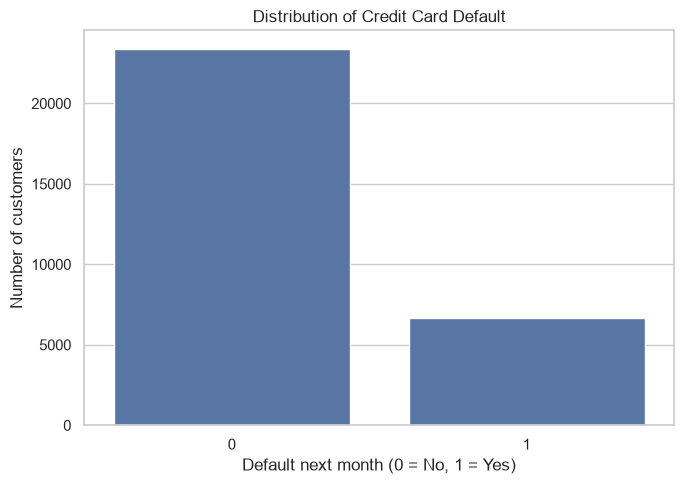

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="DEFAULT")
plt.title("Distribution of Credit Card Default")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

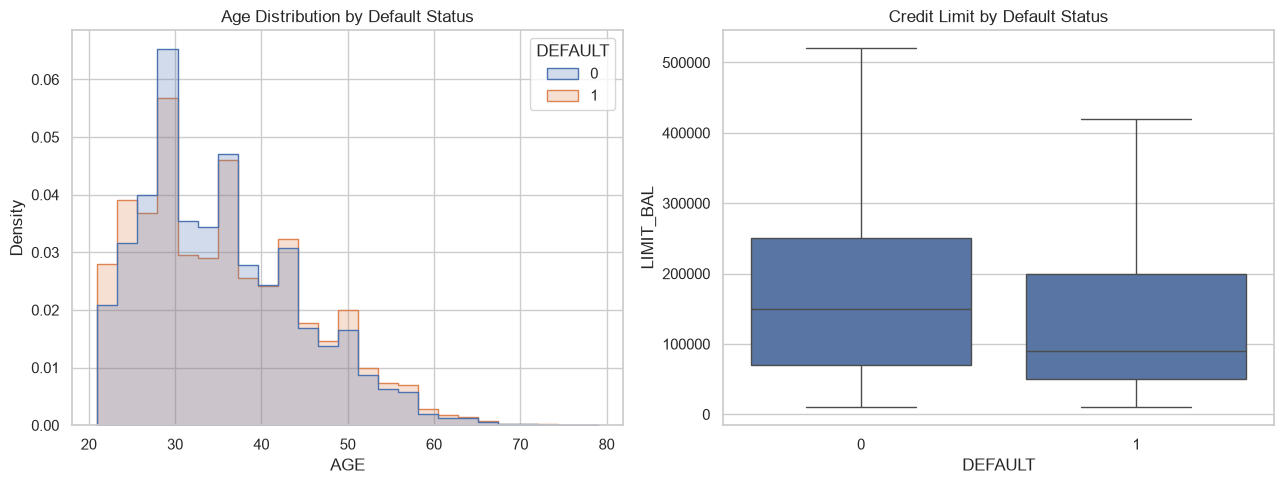

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=df, x="AGE", hue="DEFAULT",
    bins=25, element="step", stat="density",
    common_norm=False, ax=axes[0]
)
axes[0].set_title("Age Distribution by Default Status")

sns.boxplot(
    data=df, x="DEFAULT", y="LIMIT_BAL",
    showfliers=False, ax=axes[1]
)
axes[1].set_title("Credit Limit by Default Status")

plt.tight_layout()
plt.show()

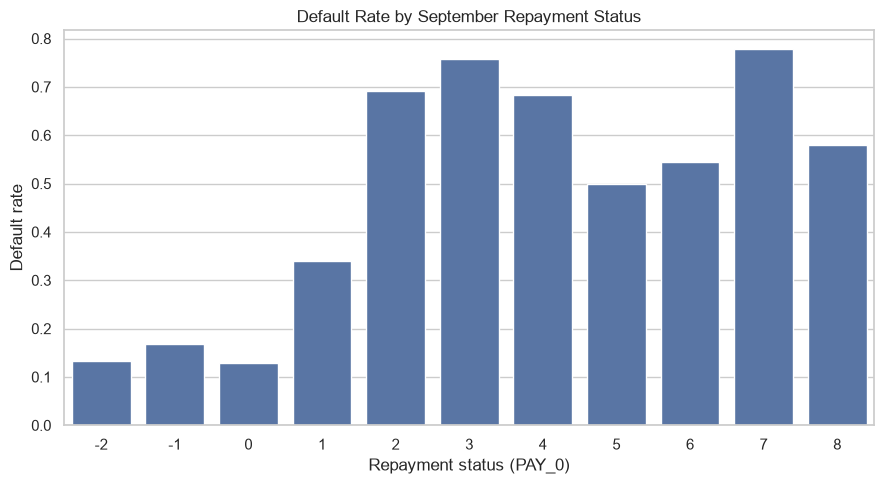


Default rate by PAY_0:
PAY_0
-2    0.132
-1    0.168
 0    0.128
 1    0.339
 2    0.691
 3    0.758
 4    0.684
 5    0.500
 6    0.545
 7    0.778
 8    0.579
Name: DEFAULT, dtype: float64

Default rate by PAY_2:
PAY_2
-2    0.183
-1    0.160
 0    0.159
 1    0.179
 2    0.556
 3    0.617
 4    0.505
 5    0.600
 6    0.750
 7    0.600
 8    0.000
Name: DEFAULT, dtype: float64

Default rate by PAY_3:
PAY_3
-2    0.185
-1    0.156
 0    0.175
 1    0.250
 2    0.516
 3    0.575
 4    0.579
 5    0.571
 6    0.609
 7    0.815
 8    0.667
Name: DEFAULT, dtype: float64

Default rate by PAY_4:
PAY_4
-2    0.193
-1    0.159
 0    0.183
 1    0.500
 2    0.523
 3    0.611
 4    0.667
 5    0.514
 6    0.400
 7    0.828
 8    0.500
Name: DEFAULT, dtype: float64

Default rate by PAY_5:
PAY_5
-2    0.197
-1    0.162
 0    0.189
 2    0.542
 3    0.635
 4    0.607
 5    0.588
 6    0.750
 7    0.828
 8    1.000
Name: DEFAULT, dtype: float64

Default rate by PAY_6:
PAY_6
-2    0.200
-1    0.17

In [7]:
pay_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

default_rates = df.groupby("PAY_0")["DEFAULT"].mean()

plt.figure(figsize=(9, 5))
sns.barplot(x=default_rates.index, y=default_rates.values)
plt.title("Default Rate by September Repayment Status")
plt.xlabel("Repayment status (PAY_0)")
plt.ylabel("Default rate")
plt.tight_layout()
plt.show()

# Compare default rates across all repayment months
for col in pay_columns:
    print(f"\nDefault rate by {col}:")
    print(df.groupby(col)["DEFAULT"].mean().round(3))

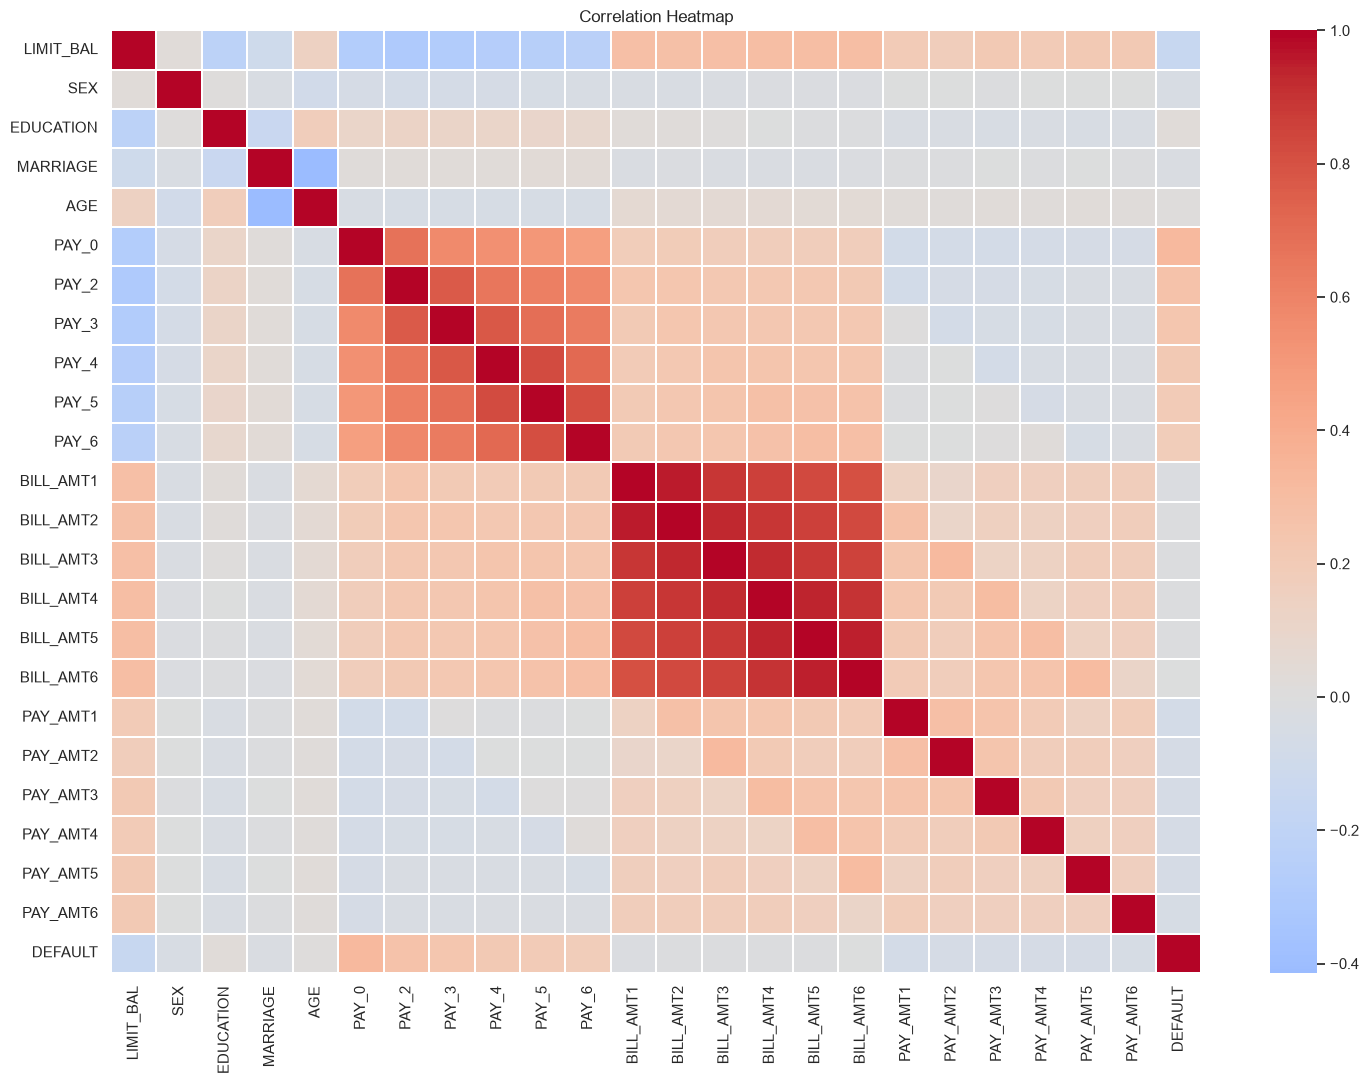

PAY_0        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
LIMIT_BAL   -0.153520
PAY_AMT1    -0.072929
PAY_AMT2    -0.058579
PAY_AMT4    -0.056827
PAY_AMT3    -0.056250
PAY_AMT5    -0.055124
PAY_AMT6    -0.053183
SEX         -0.039961
EDUCATION    0.028006
MARRIAGE    -0.024339
BILL_AMT1   -0.019644
BILL_AMT2   -0.014193
BILL_AMT3   -0.014076
AGE          0.013890
BILL_AMT4   -0.010156
BILL_AMT5   -0.006760
BILL_AMT6   -0.005372
Name: DEFAULT, dtype: float64


In [8]:
plt.figure(figsize=(15, 11))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print(
    correlation["DEFAULT"]
    .drop("DEFAULT")
    .sort_values(key=abs, ascending=False)
)

In [9]:
# Inspect category counts
for col in ["EDUCATION", "MARRIAGE"]:
    print(f"\n{col} category counts:")
    print(df[col].value_counts().sort_index())

# Check whether categories have different default rates
for col in ["EDUCATION", "MARRIAGE"]:
    print(f"\nDefault rate by {col}:")
    print(df.groupby(col)["DEFAULT"].agg(
        customers="count",
        default_rate="mean"
    ).round(3))


EDUCATION category counts:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE category counts:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Default rate by EDUCATION:
           customers  default_rate
EDUCATION                         
0                 14         0.000
1              10585         0.192
2              14030         0.237
3               4917         0.252
4                123         0.057
5                280         0.064
6                 51         0.157

Default rate by MARRIAGE:
          customers  default_rate
MARRIAGE                         
0                54         0.093
1             13659         0.235
2             15964         0.209
3               323         0.260


In [11]:
correlations = (
    df.corr(numeric_only=True)["DEFAULT"]
    .drop("DEFAULT")
    .sort_values(key=abs, ascending=False)
)

print("Top 5 correlated predictors:")
print(correlations.head(5).round(4))

Top 5 correlated predictors:
PAY_0    0.3248
PAY_2    0.2636
PAY_3    0.2353
PAY_4    0.2166
PAY_5    0.2041
Name: DEFAULT, dtype: float64


In [12]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Keep the original df unchanged
df_model = df.copy()

# Combine undocumented/other education categories
df_model["EDUCATION"] = df_model["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

# Treat unknown marriage status as the existing "other" category
df_model["MARRIAGE"] = df_model["MARRIAGE"].replace({
    0: 3
})

# Separate predictors and target
X = df_model.drop(columns="DEFAULT")
y = df_model["DEFAULT"].astype(int)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(4))

X_train: (24000, 23)
X_test: (6000, 23)

Training target proportions:
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Testing target proportions:
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 14
Categorical features: 9


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "LDA": LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    ),
    "QDA": QuadraticDiscriminantAnalysis(
        reg_param=0.1
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).set_index("Model")

print(results_df.round(4))

                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                              
Logistic Regression    0.7752     0.4926  0.5554    0.5221   0.7587
LDA                    0.8175     0.6429  0.3934    0.4881   0.7590
QDA                    0.7873     0.5203  0.4936    0.5066   0.7399


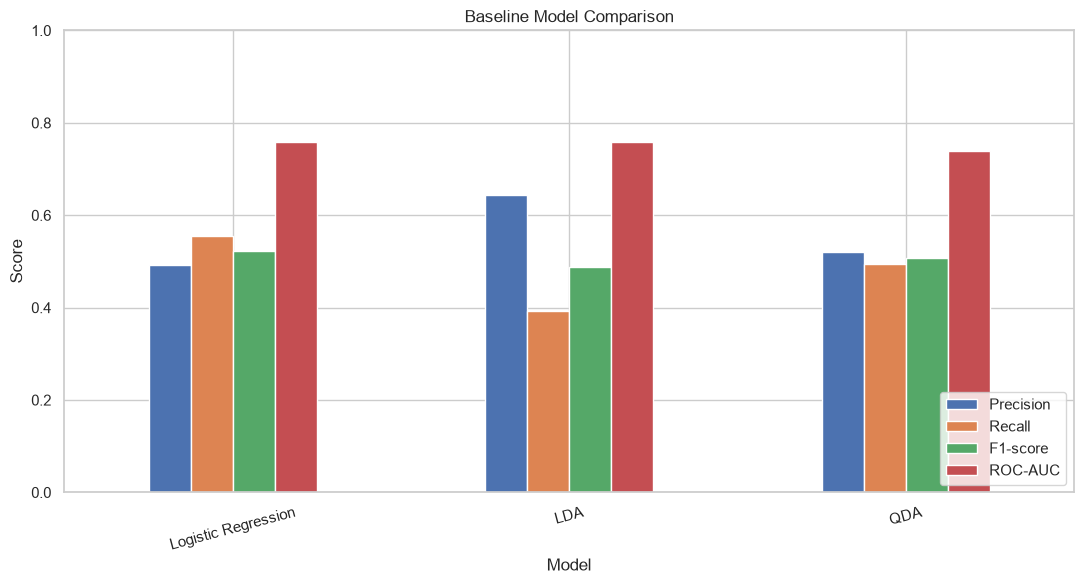

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_to_plot = [
    "Precision", "Recall", "F1-score", "ROC-AUC"
]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

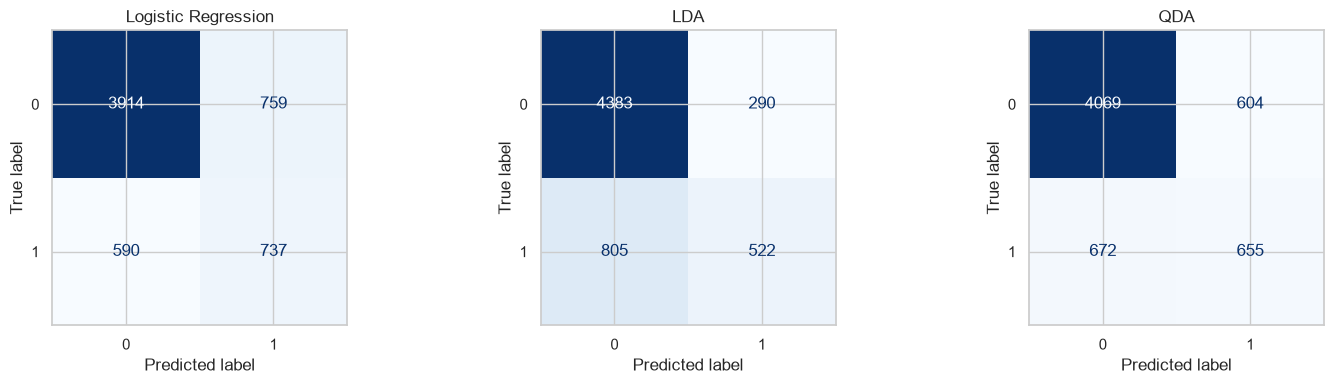

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [17]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=3000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [
        None,
        "balanced",
        {0: 1, 1: 1.5},
        {0: 1, 1: 2}
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best cross-validation F1: 0.5337


In [18]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix
)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0     0.8690    0.8376    0.8530      4673
           1     0.4926    0.5554    0.5221      1327

    accuracy                         0.7752      6000
   macro avg     0.6808    0.6965    0.6876      6000
weighted avg     0.7858    0.7752    0.7798      6000

Test ROC-AUC: 0.7587
Confusion matrix:
[[3914  759]
 [ 590  737]]


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=123,
    stratify=y_train
)

# Clone the tuned model configuration
threshold_model = clone(best_model)

threshold_model.fit(X_subtrain, y_subtrain)

val_prob = threshold_model.predict_proba(X_val)[:, 1]

c:\Users\Naman\OneDrive\Documents\Engineering\Credit-Card-Default-Prediction\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [21]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.25     0.2427  0.9718    0.3883
      0.30     0.2680  0.9444    0.4175
      0.35     0.3157  0.8597    0.4618
      0.40     0.3889  0.7646    0.5156
      0.45     0.4510  0.6798    0.5422
      0.50     0.5026  0.6271    0.5580
      0.55     0.5424  0.5847    0.5628
      0.60     0.5849  0.5386    0.5608


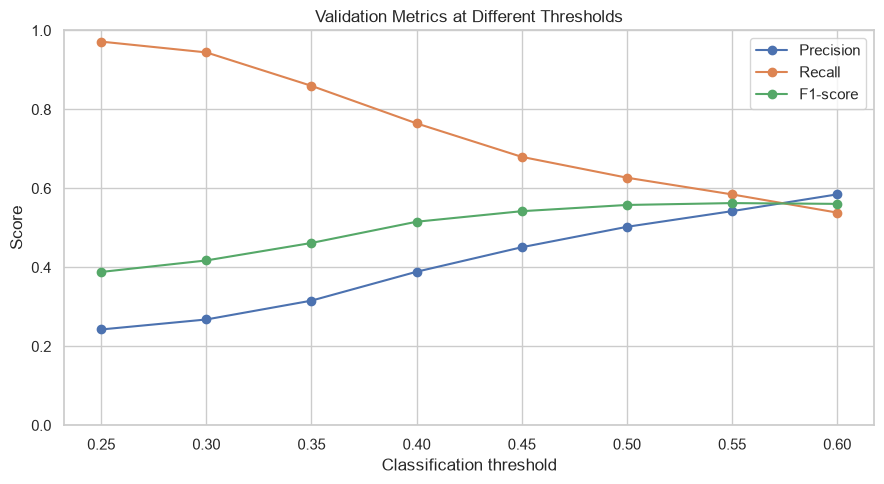

In [22]:
import matplotlib.pyplot as plt

threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1-score"]
].plot(marker="o", figsize=(9, 5))

plt.title("Validation Metrics at Different Thresholds")
plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Refit using all training data
final_model = clone(best_model)
final_model.fit(X_train, y_train)

# Predict probabilities on the test set
test_prob = final_model.predict_proba(X_test)[:, 1]

# Compare the default threshold and the selected threshold
thresholds_to_compare = [0.50, 0.55]

for threshold in thresholds_to_compare:
    test_pred = (test_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
    print("Precision:", round(
        precision_score(y_test, test_pred), 4
    ))
    print("Recall:", round(
        recall_score(y_test, test_pred), 4
    ))
    print("F1-score:", round(
        f1_score(y_test, test_pred), 4
    ))
    print("ROC-AUC:", round(
        roc_auc_score(y_test, test_prob), 4
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, test_pred))

    print("\nClassification report:")
    print(classification_report(
        y_test, test_pred, digits=4
    ))